In [8]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from data_wrangling import read_feature_set
from IPython.display import display
sns.set_theme(style="white")


In [9]:
featured_filtered, candidate_features = read_feature_set()

target = "Balancing_energy_total"

In [10]:
from data_wrangling import create_day_ahead_forecast_split

issue_time = pd.Timestamp("2025-01-14 18:00", tz='UTC')

train_df, y_train_df, forecast_df = create_day_ahead_forecast_split(
    featured_filtered,
    features=candidate_features['q50'],
    issue_time=issue_time,
    target="Balancing_energy_total",
)

print(train_df.index.min())
print(train_df.index.max())

print(forecast_df.index.min())
print(forecast_df.index.max())

print(len(forecast_df))

2023-01-01 00:00:00+00:00
2025-01-14 17:45:00+00:00
2025-01-15 00:00:00+00:00
2025-01-15 23:45:00+00:00
96


In [11]:
featured_filtered.filter(like='imbalance')

,p_DA_to_imbalance_spread,p_imbalance
Datetime,,
2023-01-01 00:00:00+00:00,-31.70,-31.80
2023-01-01 00:15:00+00:00,-31.70,-31.80
2023-01-01 00:30:00+00:00,-31.67,-31.77
2023-01-01 00:45:00+00:00,-31.67,-31.77
2023-01-01 01:00:00+00:00,-25.61,-26.94
...,...,...
2026-08-31 22:45:00+00:00,46.06,199.33
2026-08-31 23:00:00+00:00,46.06,199.33
2026-08-31 23:15:00+00:00,46.06,199.33


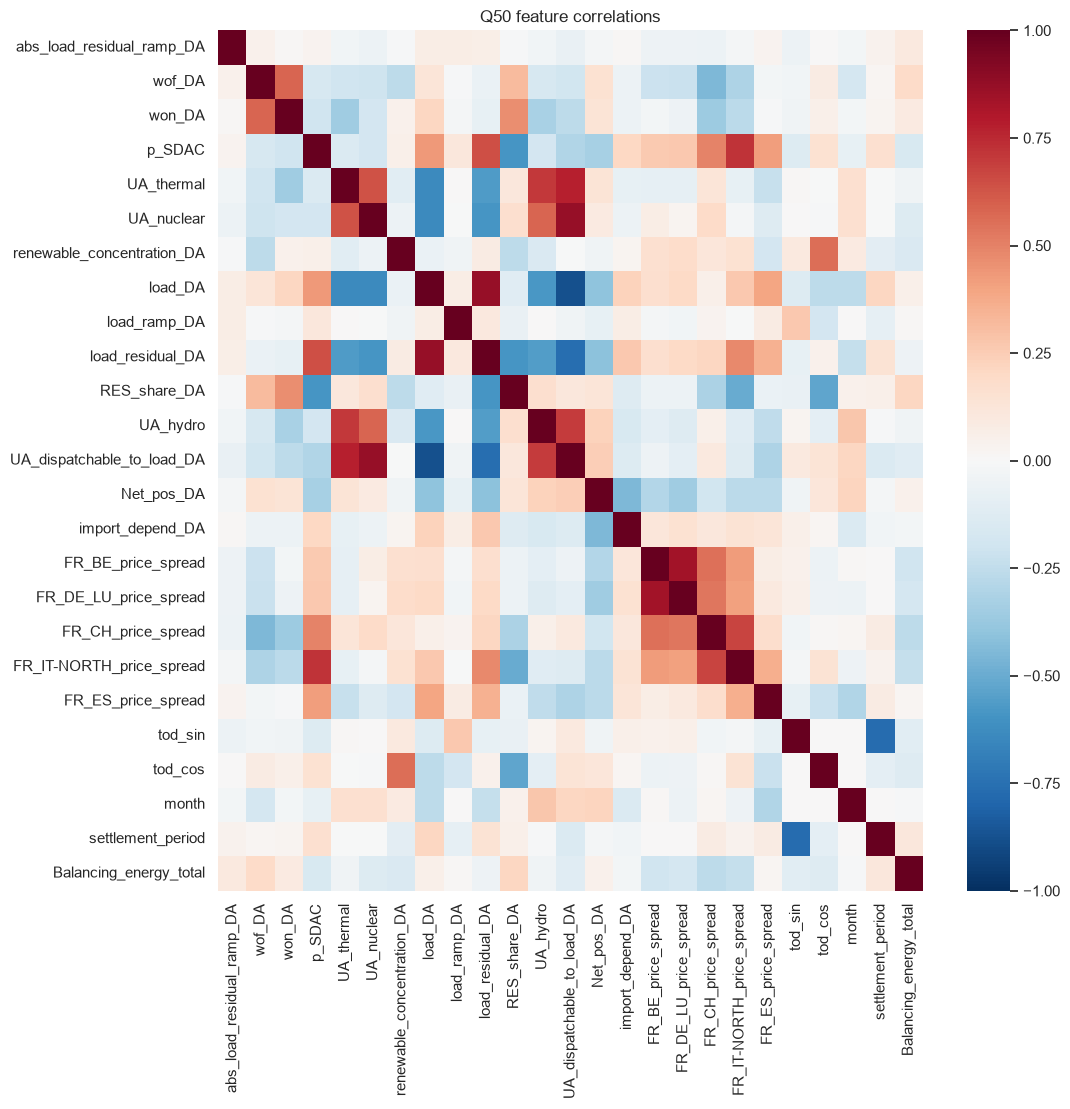

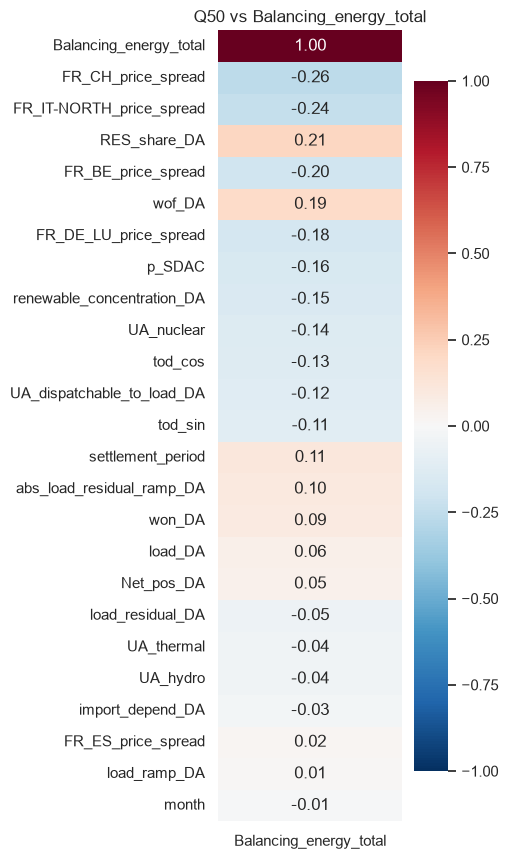


Q50


,Balancing_energy_total
FR_CH_price_spread,-0.259672
FR_IT-NORTH_price_spread,-0.239891
RES_share_DA,0.211568
FR_BE_price_spread,-0.197789
wof_DA,0.193506
FR_DE_LU_price_spread,-0.175311
p_SDAC,-0.160243
renewable_concentration_DA,-0.154524
UA_nuclear,-0.136751
tod_cos,-0.128188


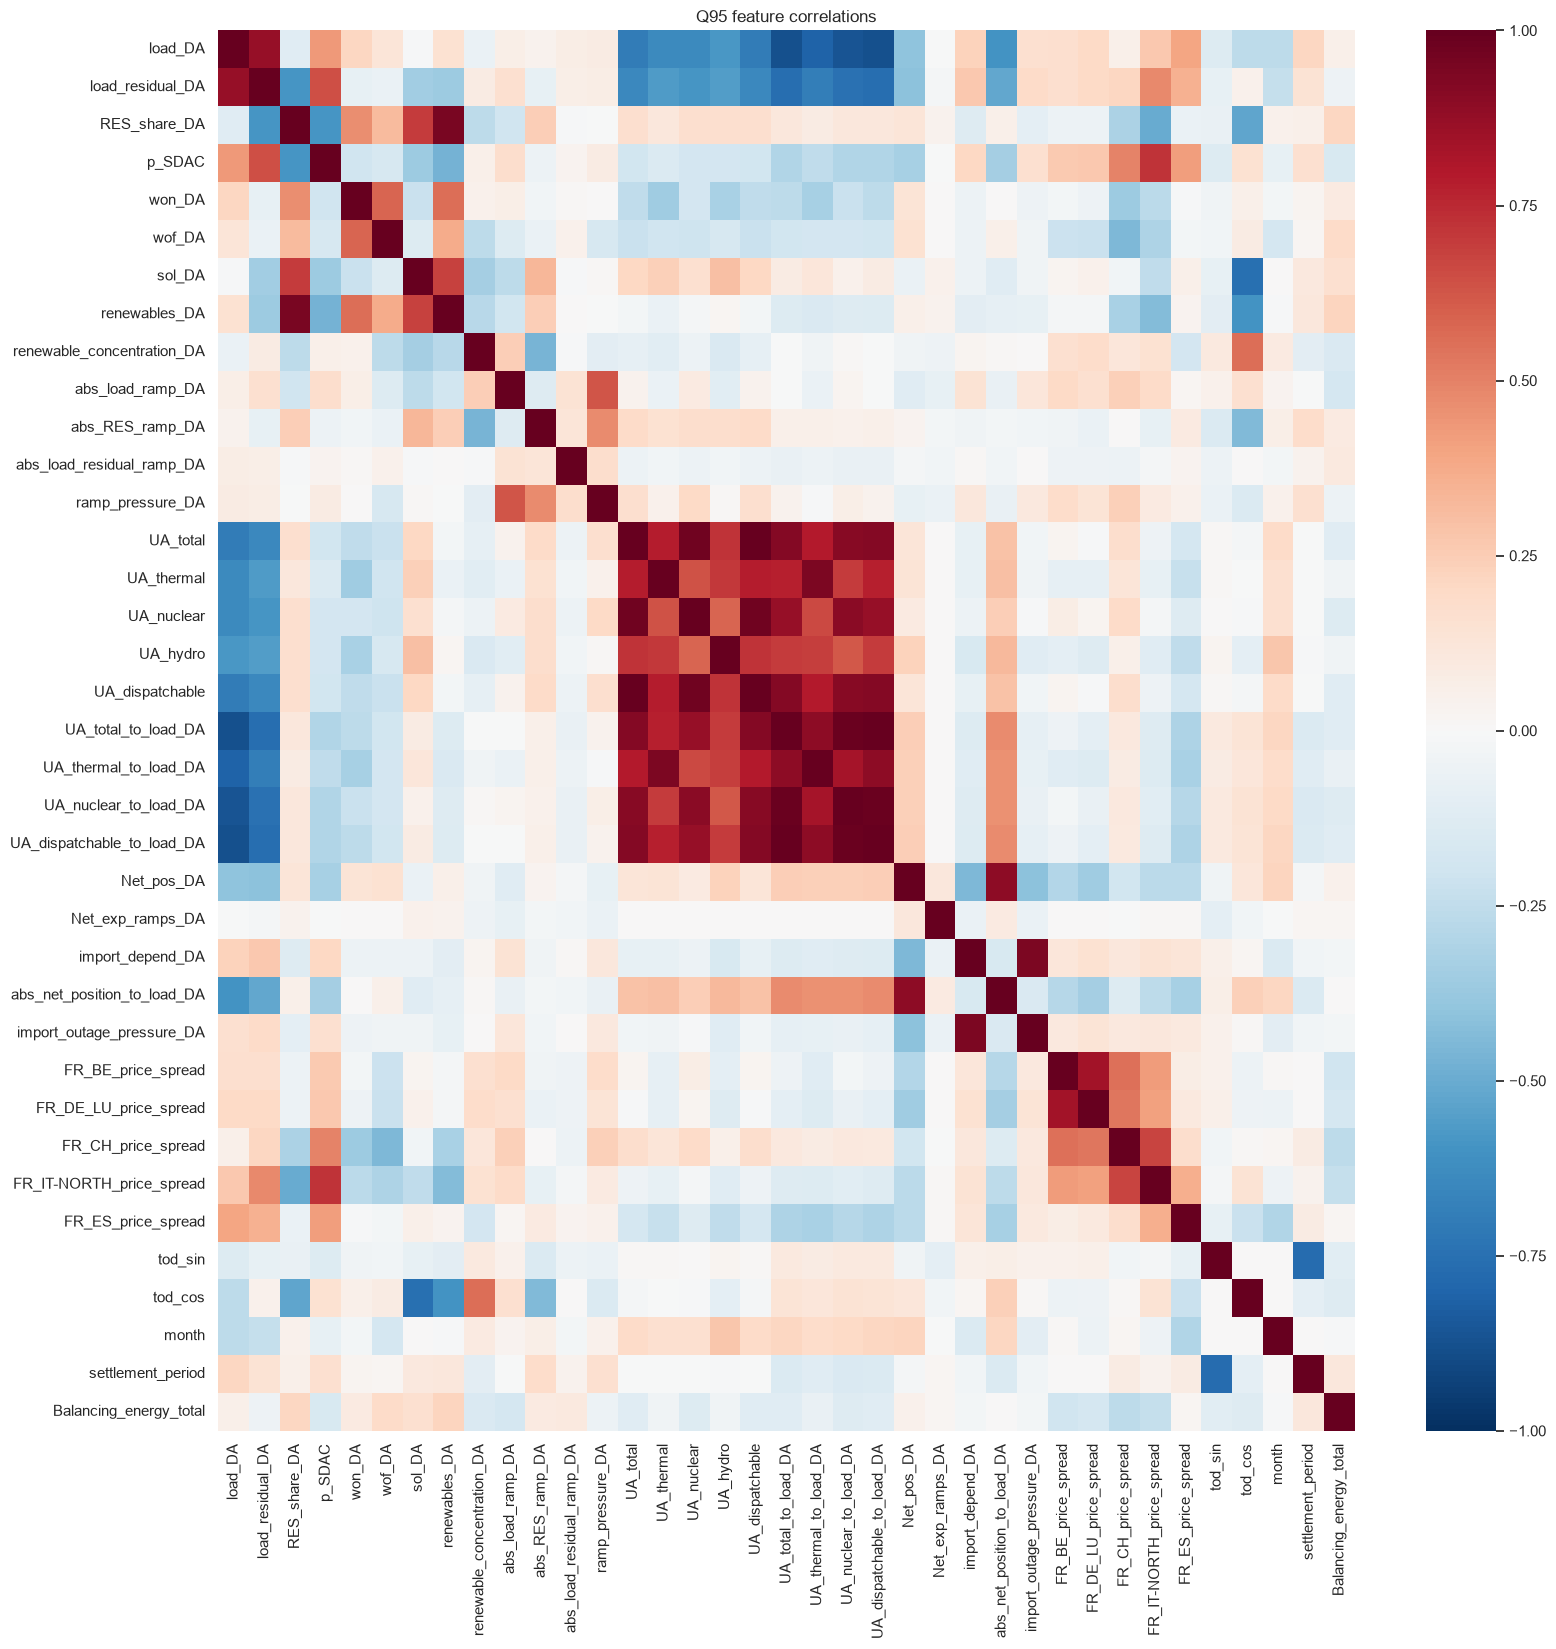

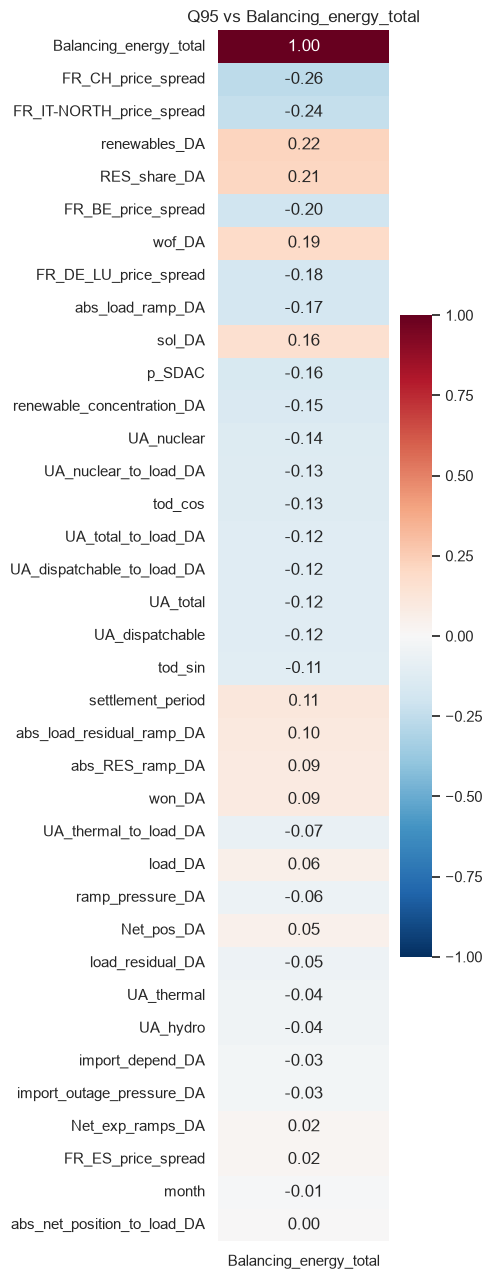


Q95


,Balancing_energy_total
FR_CH_price_spread,-0.259672
FR_IT-NORTH_price_spread,-0.239891
renewables_DA,0.220359
RES_share_DA,0.211568
FR_BE_price_spread,-0.197789
wof_DA,0.193506
FR_DE_LU_price_spread,-0.175311
abs_load_ramp_DA,-0.172988
sol_DA,0.160650
p_SDAC,-0.160243


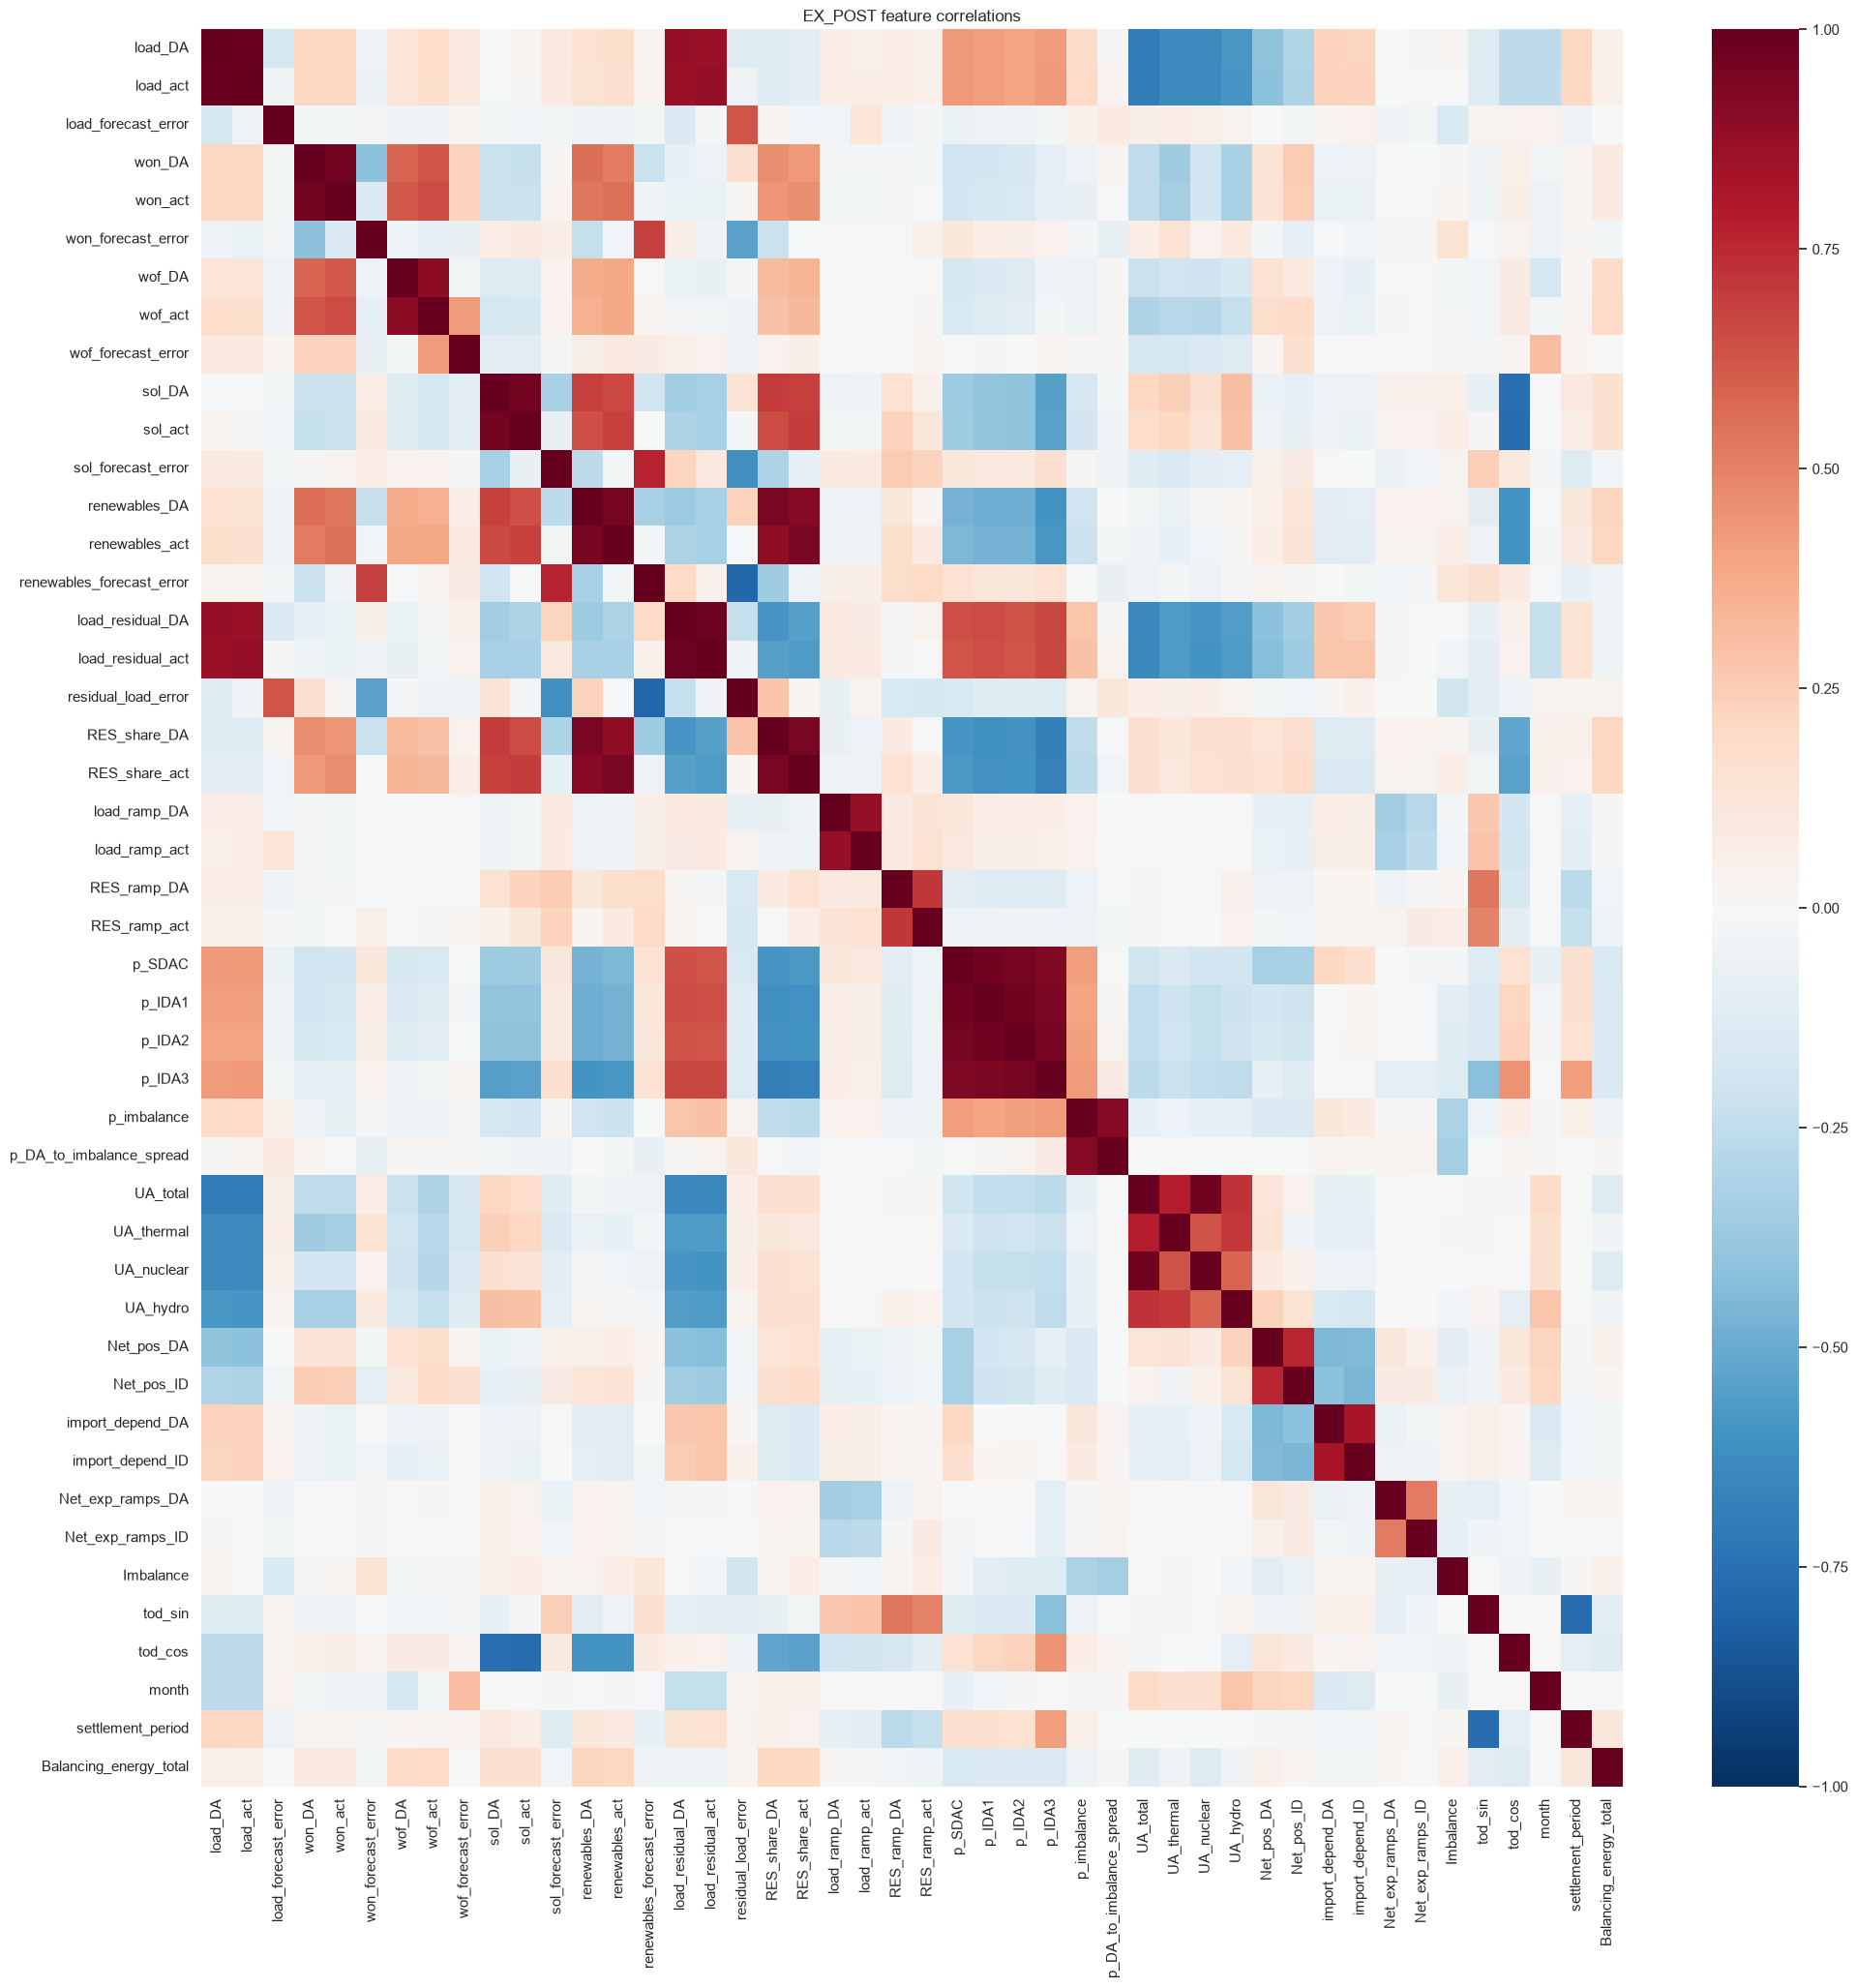

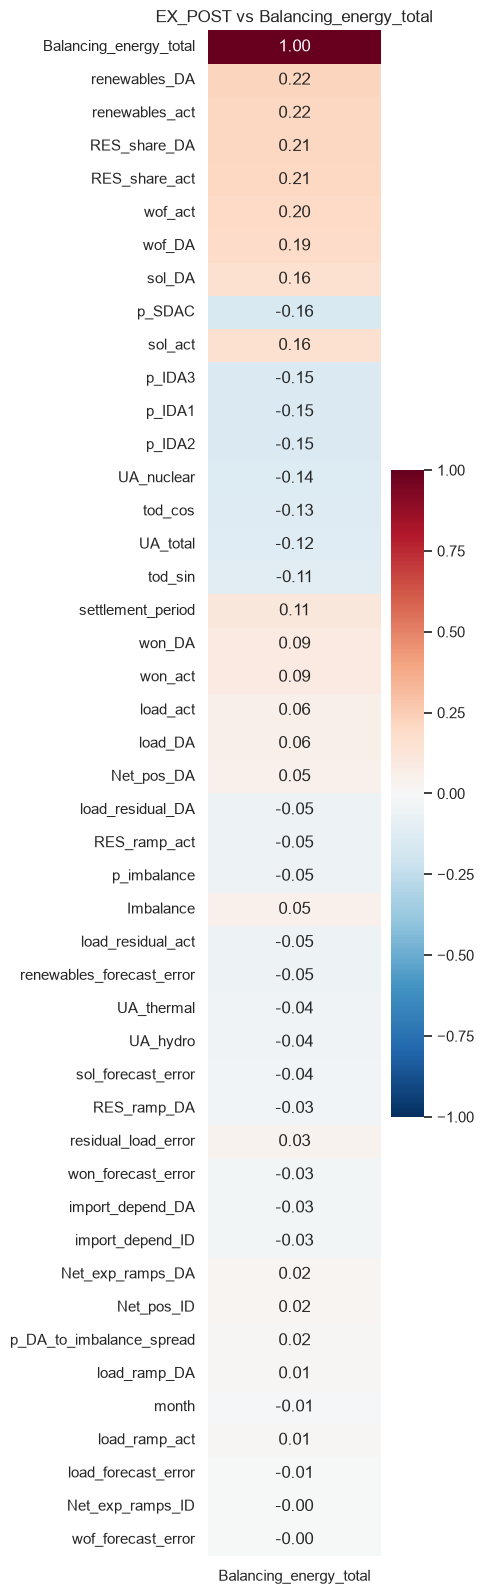


EX_POST


,Balancing_energy_total
renewables_DA,0.220359
renewables_act,0.218255
RES_share_DA,0.211568
RES_share_act,0.209961
wof_act,0.196063
wof_DA,0.193506
sol_DA,0.160650
p_SDAC,-0.160243
sol_act,0.159717
p_IDA3,-0.152383


In [12]:
for feature_set_name in ["q50", "q95", "ex_post"]:

    features = candidate_features[feature_set_name]

    data = (
        featured_filtered[
            features + [target]
        ]
        .select_dtypes("number")
    )

    # =========================================================================
    # FULL CORRELATION MATRIX
    # =========================================================================

    corr = data.corr()

    plt.figure(
        figsize=(
            max(10, len(corr) * 0.45),
            max(8, len(corr) * 0.45),
        )
    )

    sns.heatmap(
        corr,
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
    )

    plt.title(
        f"{feature_set_name.upper()} feature correlations"
    )

    plt.tight_layout()
    plt.show()

    # =========================================================================
    # CORRELATION WITH RESPONSE
    # =========================================================================

    corr_target = (
        corr[[target]]
        .sort_values(
            target,
            key=np.abs,
            ascending=False,
        )
    )

    plt.figure(
        figsize=(
            5,
            max(6, len(corr_target) * 0.35),
        )
    )

    sns.heatmap(
        corr_target,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
    )

    plt.title(
        f"{feature_set_name.upper()} vs {target}"
    )

    plt.tight_layout()
    plt.show()

    print("\n" + "=" * 80)
    print(feature_set_name.upper())
    print("=" * 80)

    display(
        corr_target
        .drop(index=target)
        .sort_values(
            target,
            key=np.abs,
            ascending=False,
        )
        .head(25)
    )


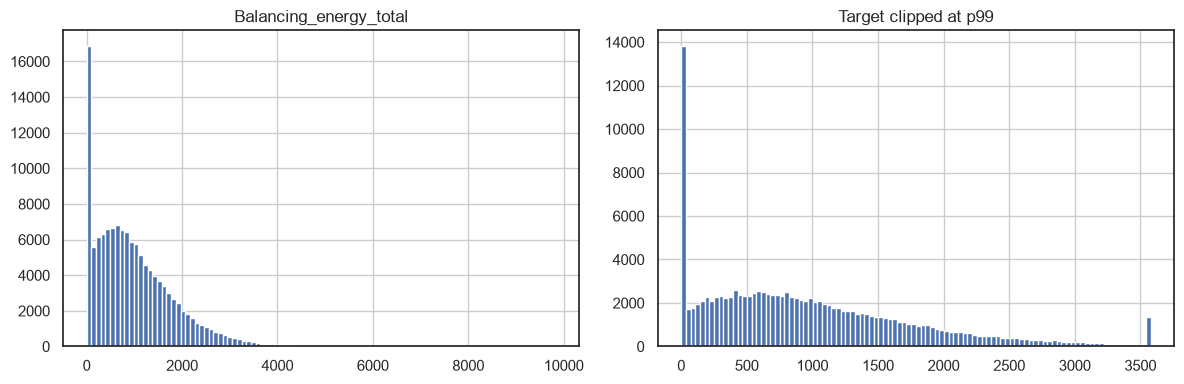

In [13]:
# ============================================================================
# DISTRIBUTION OF TARGET
# ============================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
)

featured_filtered[target].hist(
    bins=100,
    ax=axes[0],
)

axes[0].set_title(target)

featured_filtered[target].clip(
    upper=featured_filtered[target].quantile(0.99)
).hist(
    bins=100,
    ax=axes[1],
)

axes[1].set_title("Target clipped at p99")

plt.tight_layout()
plt.show()

In [14]:
# ============================================================================
# COMBINED CORRELATION RANKING
# ============================================================================

all_features = sorted(
    set(
        candidate_features["q50"]
        + candidate_features["q95"]
        + candidate_features["ex_post"]
    )
)

corrs = (
    featured_filtered[
        all_features + [target]
    ]
    .select_dtypes("number")
    .corr()[target]
    .drop(target)
    .sort_values(
        key=np.abs,
        ascending=False,
    )
)

display(corrs.head(50))


FR_CH_price_spread           -0.259672
FR_IT-NORTH_price_spread     -0.239891
renewables_DA                 0.220359
renewables_act                0.218255
RES_share_DA                  0.211568
RES_share_act                 0.209961
FR_BE_price_spread           -0.197789
wof_act                       0.196063
wof_DA                        0.193506
FR_DE_LU_price_spread        -0.175311
abs_load_ramp_DA             -0.172988
sol_DA                        0.160650
p_SDAC                       -0.160243
sol_act                       0.159717
renewable_concentration_DA   -0.154524
p_IDA3                       -0.152383
p_IDA1                       -0.149721
p_IDA2                       -0.148810
UA_nuclear                   -0.136751
UA_nuclear_to_load_DA        -0.131957
tod_cos                      -0.128188
UA_total_to_load_DA          -0.120821
UA_dispatchable_to_load_DA   -0.120767
UA_total                     -0.118789
UA_dispatchable              -0.118639
tod_sin                  

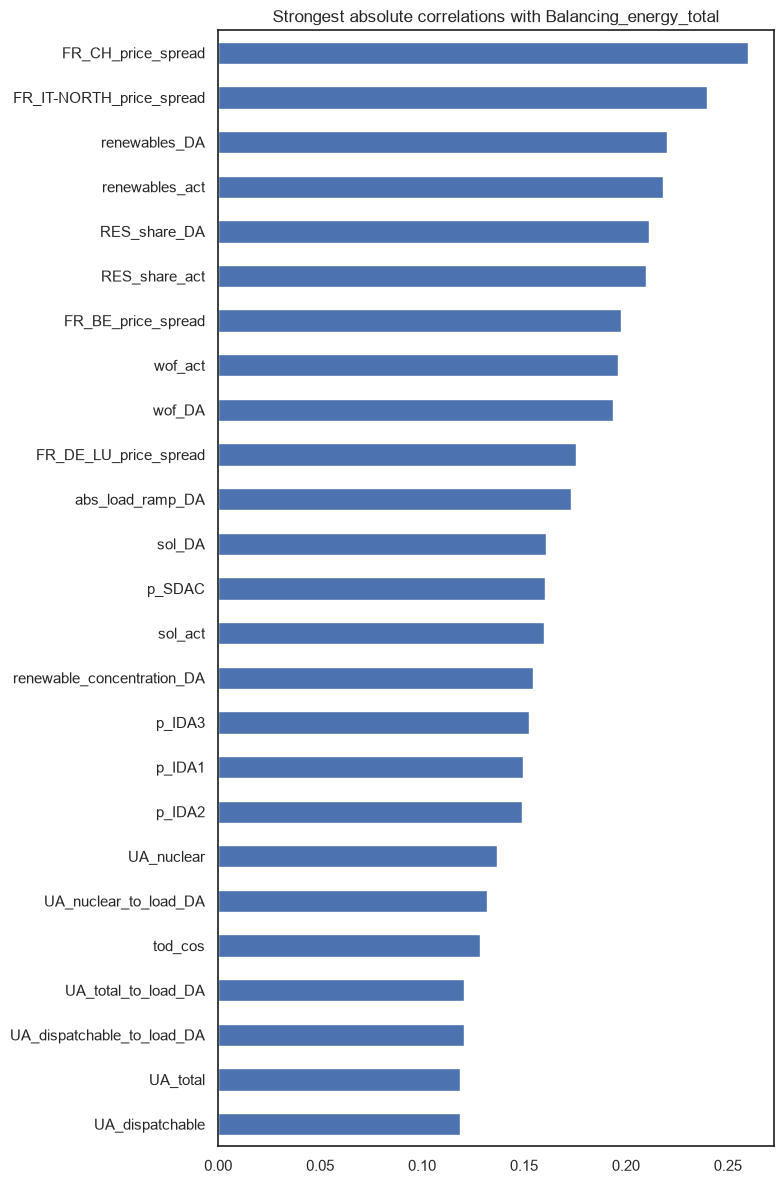

In [15]:
# ============================================================================
# STRONGEST ABSOLUTE CORRELATIONS
# ============================================================================

fig, ax = plt.subplots(
    figsize=(8, 12)
)

corrs.abs().head(25).sort_values().plot.barh(ax=ax)

ax.set_title(
    f"Strongest absolute correlations with {target}"
)

plt.tight_layout()
plt.show()


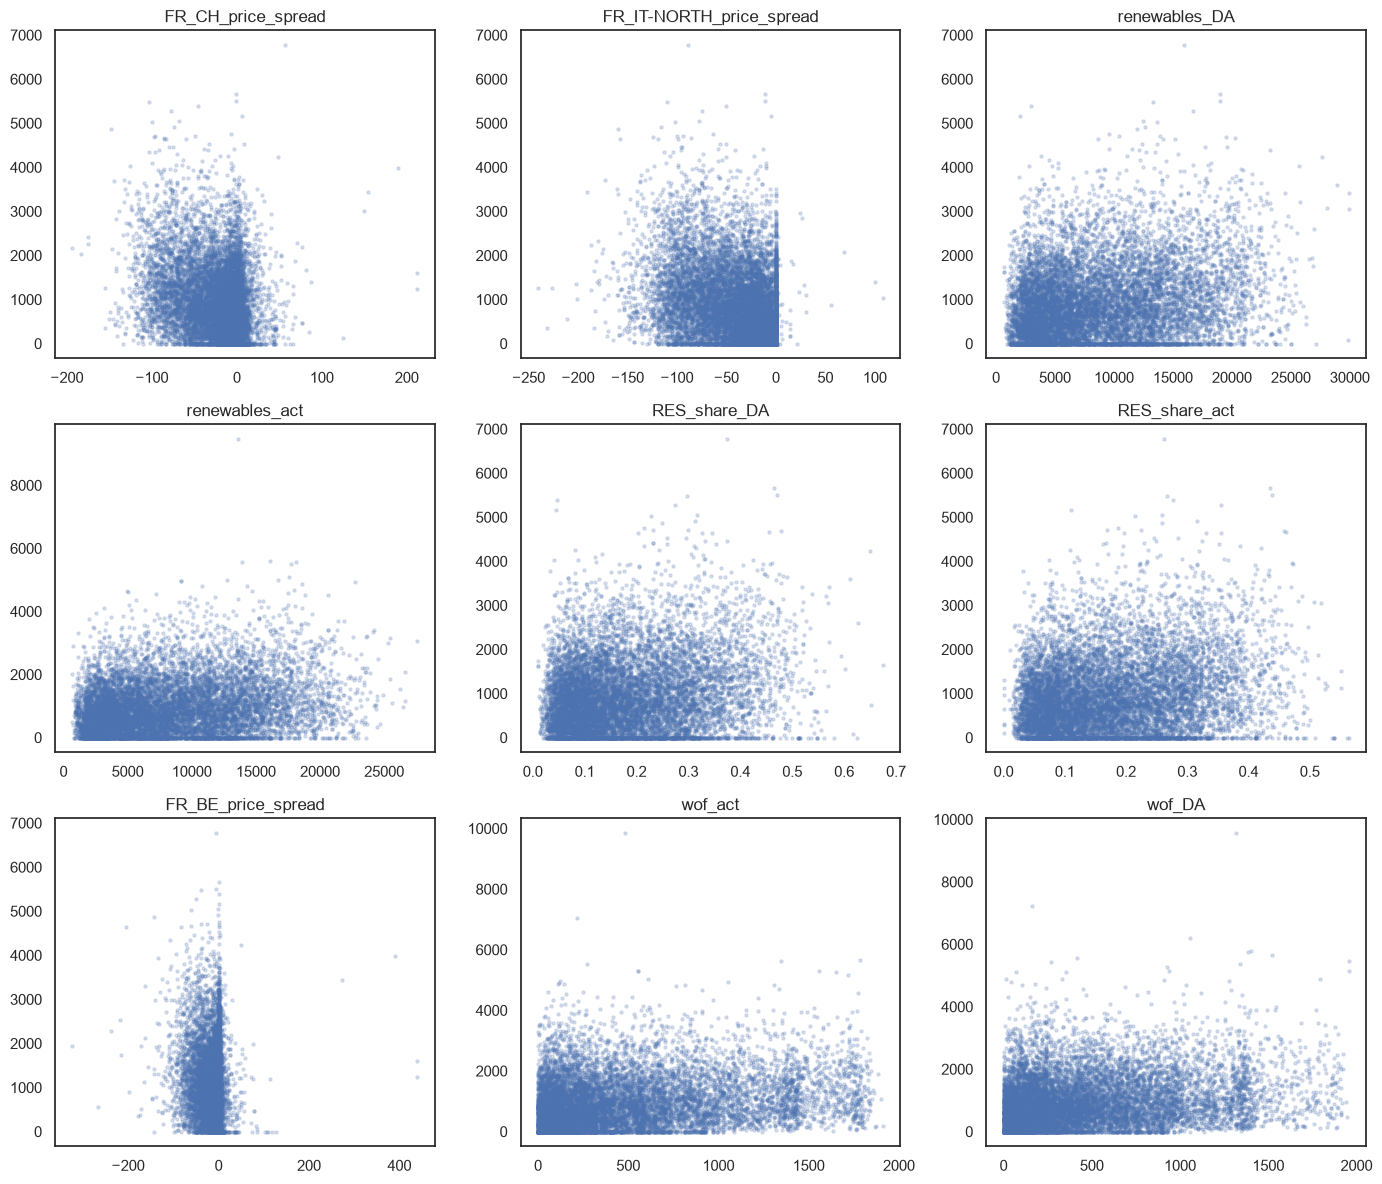

In [16]:
# ============================================================================
# SCATTER PLOTS OF STRONGEST DRIVERS
# ============================================================================

top_features = (
    corrs.abs()
    .head(9)
    .index
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(14, 12),
)

for feature, ax in zip(
    top_features,
    axes.flat,
):

    sample = (
        featured_filtered[
            [feature, target]
        ]
        .dropna()
    )

    if len(sample) > 10_000:
        sample = sample.sample(
            10_000,
            random_state=42,
        )

    ax.scatter(
        sample[feature],
        sample[target],
        alpha=0.2,
        s=5,
    )

    ax.set_title(feature)

plt.tight_layout()
plt.show()


In [17]:
# ============================================================================
# COMPARE EXTREME EVENTS vs NORMAL EVENTS
# ============================================================================

threshold = (
    featured_filtered[target]
    .quantile(0.95)
)

featured_filtered["is_extreme"] = (
    featured_filtered[target]
    >= threshold
)


In [18]:
# Focus on q95 candidates first

summary = (
    featured_filtered
    .groupby("is_extreme")[
        candidate_features["q95"]
    ]
    .mean()
    .T
)

summary.columns = [
    "normal",
    "extreme",
]

summary["change_pct"] = (
    100
    * (
        summary["extreme"]
        - summary["normal"]
    )
    / summary["normal"].abs()
)

summary = summary.sort_values(
    "change_pct",
    key=np.abs,
    ascending=False,
)

display(summary.head(30))


,normal,extreme,change_pct
Net_exp_ramps_DA,-0.975762,114.003786,11783.568001
tod_cos,0.013667,-0.259648,-1999.751089
tod_sin,0.011079,-0.210467,-1999.751089
FR_ES_price_spread,1.475606,4.688474,217.732170
FR_BE_price_spread,-13.661340,-26.450888,-93.618545
FR_DE_LU_price_spread,-17.367607,-33.062558,-90.369104
FR_CH_price_spread,-25.386630,-46.632052,-83.687443
sol_DA,3118.978116,5311.940493,70.310284
FR_IT-NORTH_price_spread,-47.471731,-69.291837,-45.964422
import_depend_DA,0.002549,0.001431,-43.866389


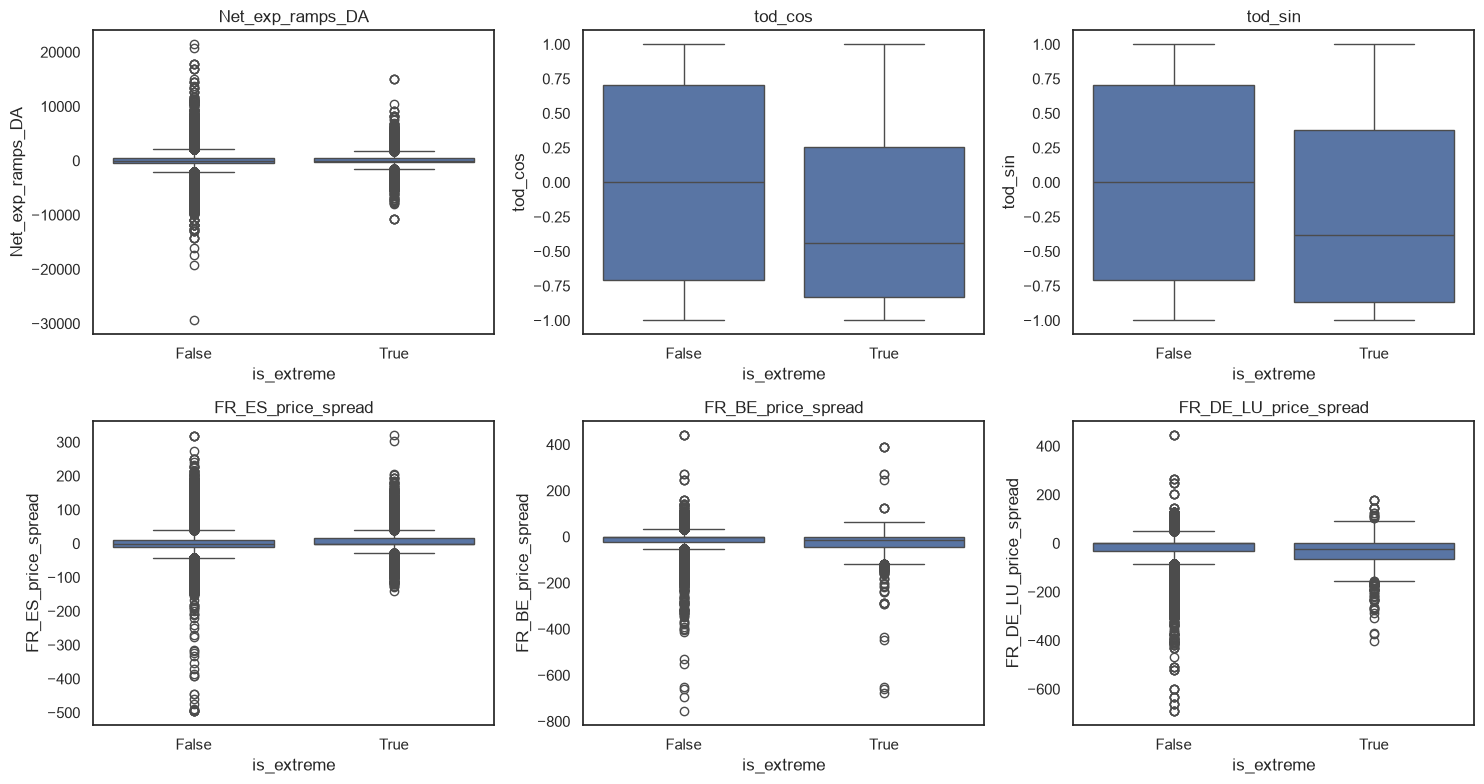

In [ ]:
# ============================================================================
# FEATURE DISTRIBUTIONS DURING EXTREME EVENTS
# ============================================================================

top_extreme_features = (
    summary["change_pct"]
    .abs()
    .head(15)
    .index
)

fig, axes = plt.subplots(
    5,
    3,
    figsize=(15, 8),
)

for feature, ax in zip(
    top_extreme_features,
    axes.flat,
):

    sns.boxplot(
        data=featured_filtered[
            [feature, "is_extreme"]
        ],
        x="is_extreme",
        y=feature,
        ax=ax,
    )

    ax.set_title(feature)

plt.tight_layout()
plt.show()


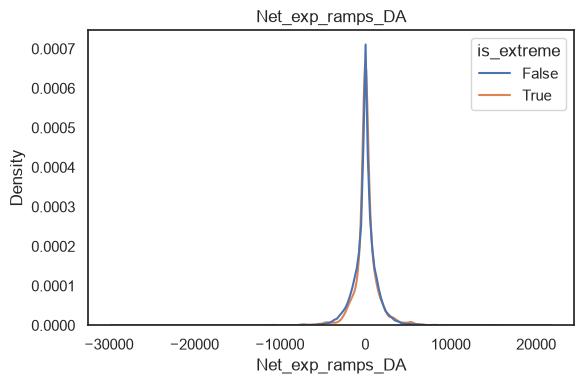

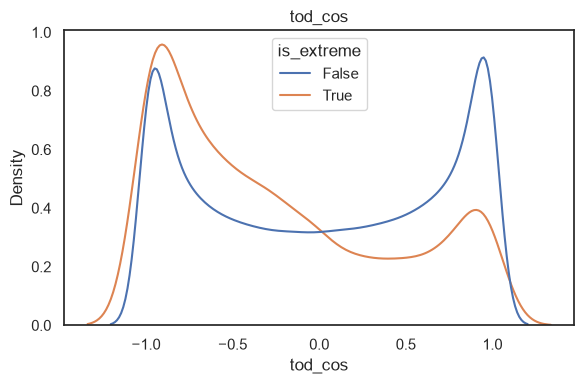

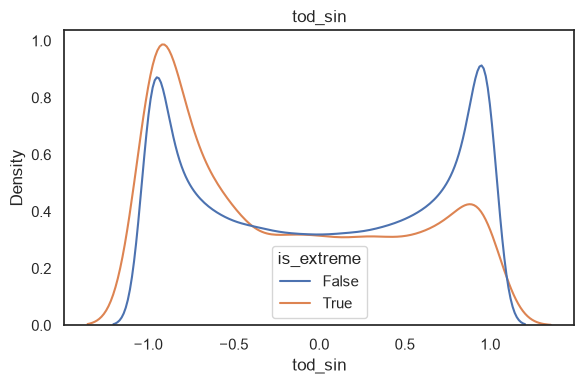

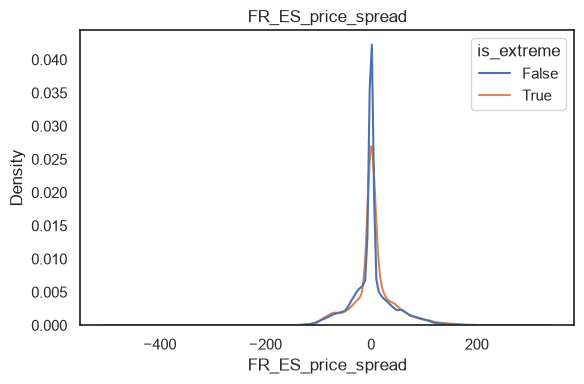

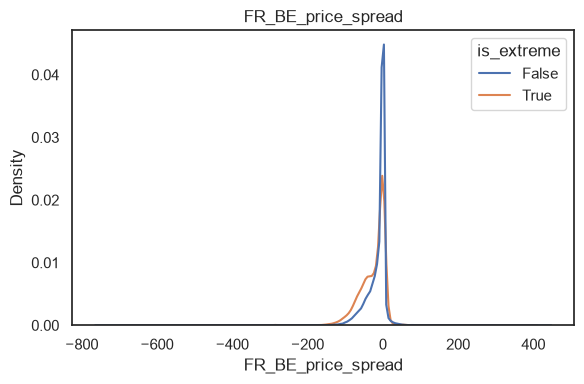

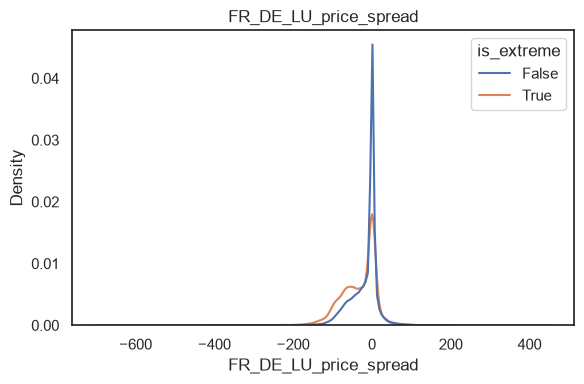

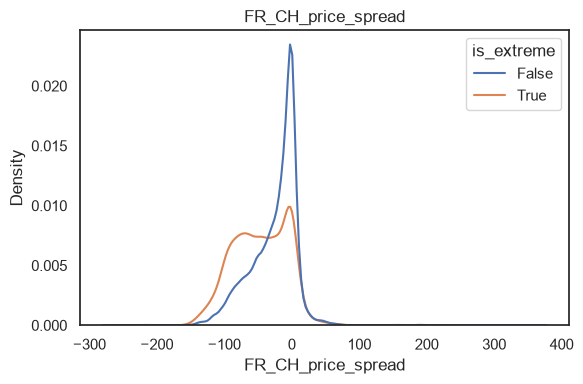

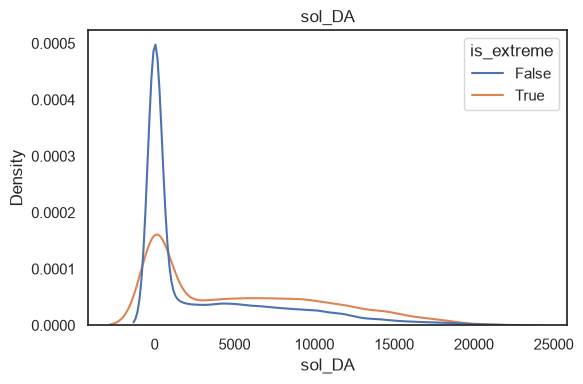

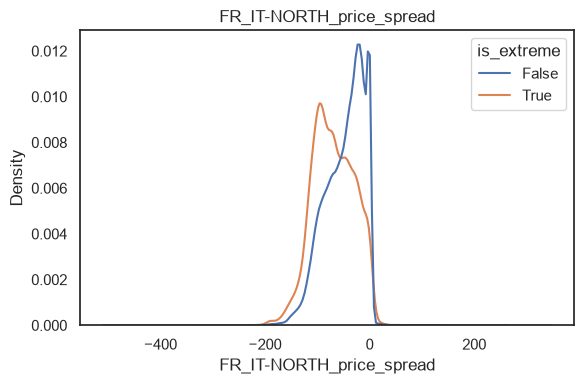

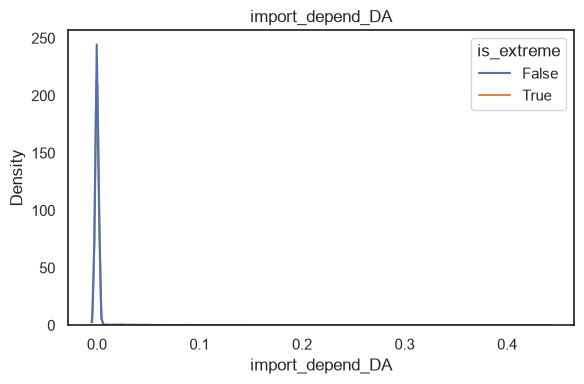

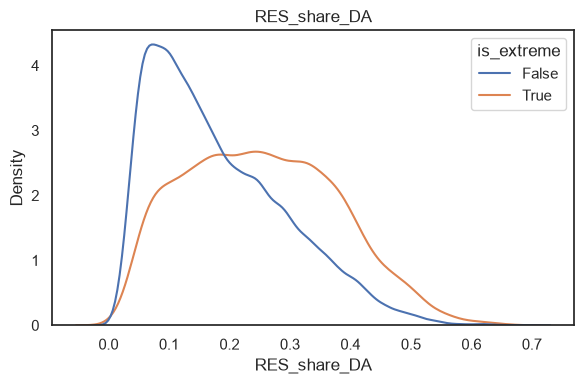

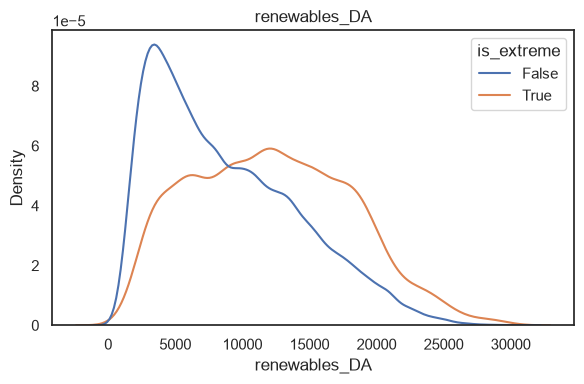

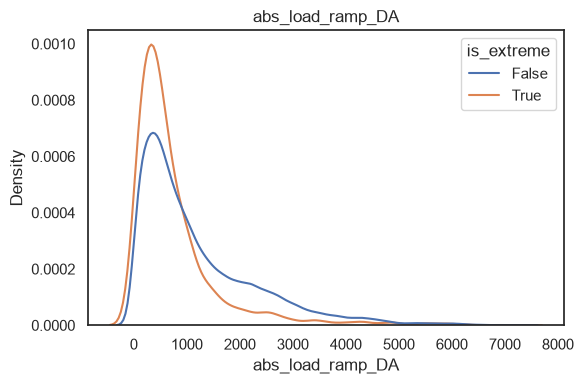

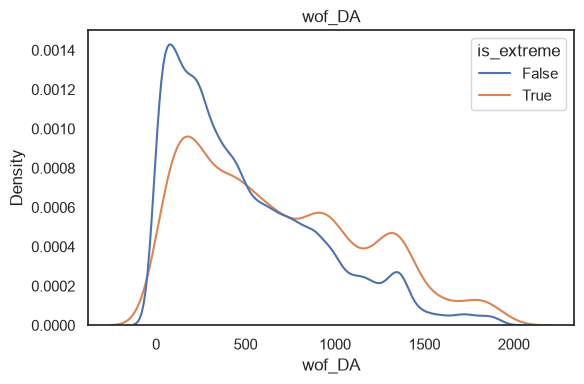

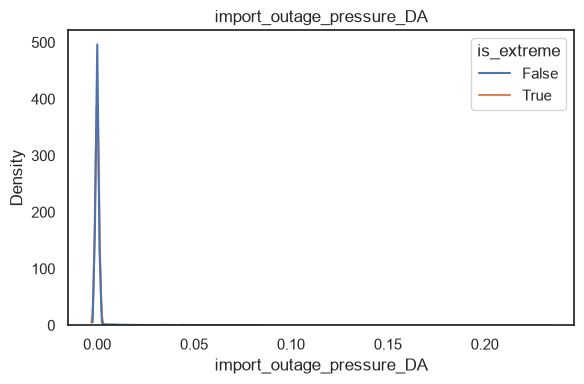

In [25]:
# ============================================================================
# OPTIONAL: FEATURE DISTRIBUTIONS
# ============================================================================

for feature in top_extreme_features:

    fig, ax = plt.subplots(
        figsize=(6, 4)
    )

    sns.kdeplot(
        data=featured_filtered,
        x=feature,
        hue="is_extreme",
        common_norm=False,
        ax=ax,
    )

    ax.set_title(feature)

    plt.tight_layout()
    plt.show()


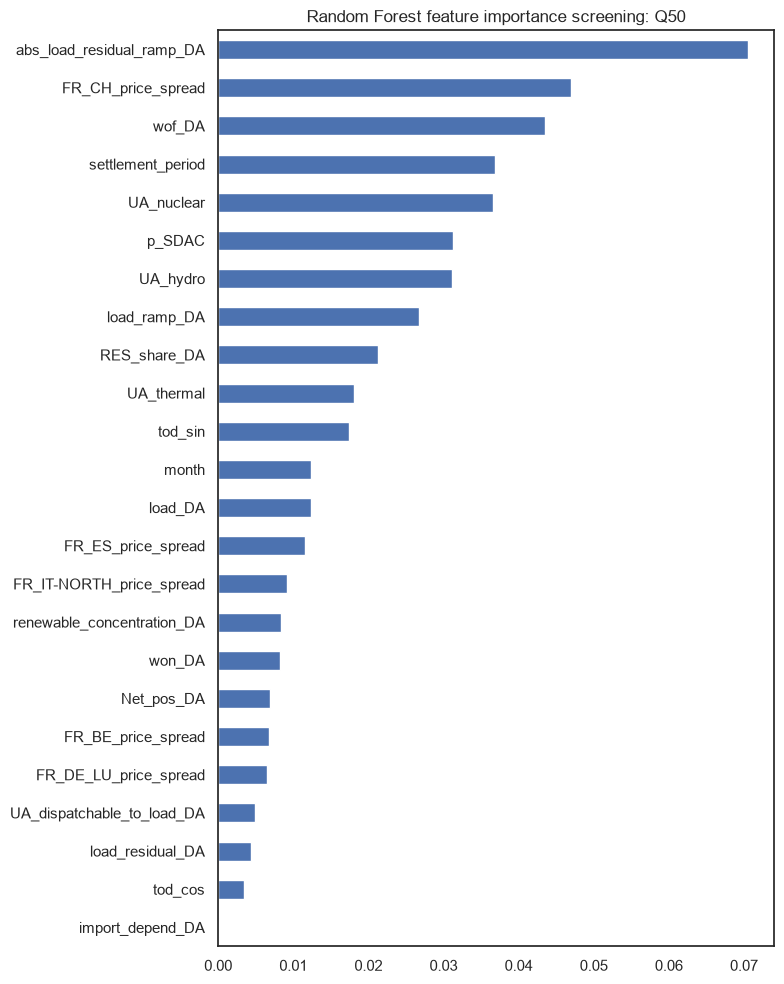

In [31]:
from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance

features = candidate_features["q50"]

data = (
    featured_filtered[
        features + [target]
    ]
    .dropna()
)

X = data[features]
# X = featured_filtered.drop(columns=[target, 'BZ', 'Imbalance', 'p_imbalance', 'p_DA_to_imbalance_spread', 'is_extreme']).dropna()
y = featured_filtered.loc[X.index, target]

model = XGBRegressor(
    objective="reg:quantileerror",
    quantile_alpha=0.5,
    n_estimators=500,
    # n_estimators=10,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)

model.fit(X, y)

result = permutation_importance(
    model,
    X,
    y,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

importance = (
    pd.Series(
        result.importances_mean,
        index=X.columns,
    )
    .sort_values(ascending=False)
)

importance.head(30)

fig, ax = plt.subplots(
    figsize=(8, 10)
)

importance.head(25).sort_values().plot.barh(
    ax=ax
)

ax.set_title(
    "Random Forest feature importance screening: Q50"
)

plt.tight_layout()
plt.show()

In [33]:
q50_features = importance.index[:10]
print('q50_features')
print(list(q50_features))

q50_features
['abs_load_residual_ramp_DA', 'FR_CH_price_spread', 'wof_DA', 'settlement_period', 'UA_nuclear', 'p_SDAC', 'UA_hydro', 'load_ramp_DA', 'RES_share_DA', 'UA_thermal']


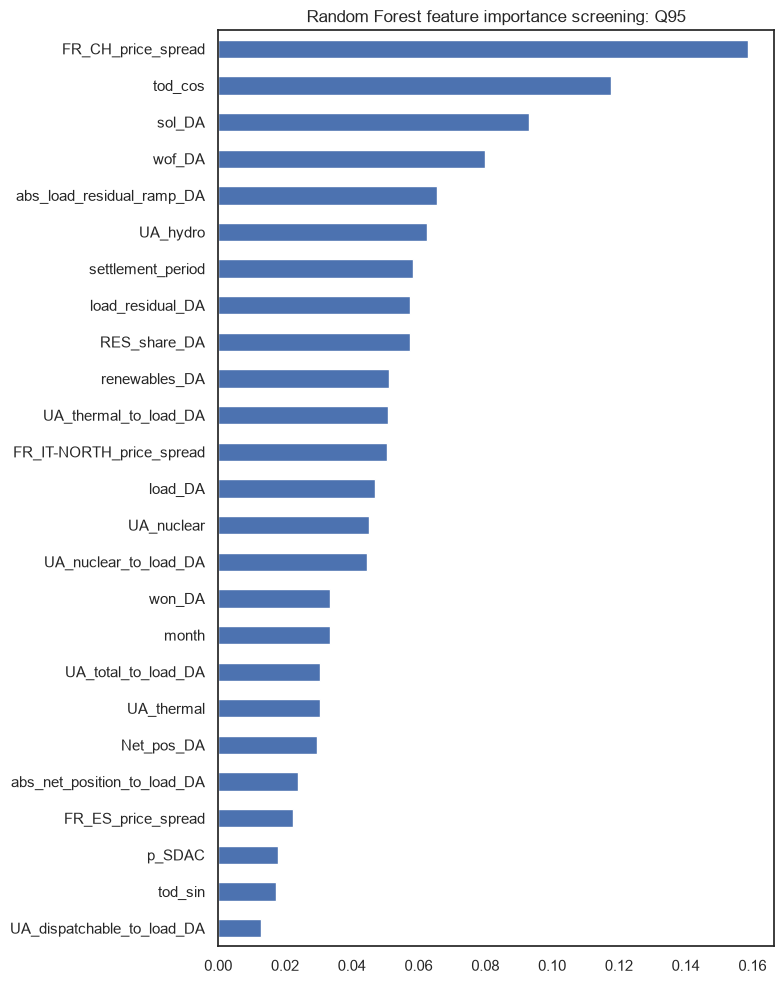

In [36]:
from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance


features = candidate_features["q95"]

data = (
    featured_filtered[
        features + [target]
    ]
    .dropna()
)

X = data[features]
# X = featured_filtered.drop(columns=[target, 'BZ', 'p_imbalance', 'is_extreme']).dropna()
y = featured_filtered.loc[X.index, target]

model = XGBRegressor(
    objective="reg:quantileerror",
    quantile_alpha=0.95,
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)

model.fit(X, y)

result = permutation_importance(
    model,
    X,
    y,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

importance = (
    pd.Series(
        result.importances_mean,
        index=X.columns,
    )
    .sort_values(ascending=False)
)

importance.head(30)

fig, ax = plt.subplots(
    figsize=(8, 10)
)

importance.head(25).sort_values().plot.barh(
    ax=ax
)

ax.set_title(
    "Random Forest feature importance screening: Q95"
)

plt.tight_layout()
plt.show()

In [35]:
q90_features = importance.index[:10]
print('q95_features')
print(list(q90_features))

q95_features
['FR_CH_price_spread', 'abs_load_residual_ramp_DA', 'UA_thermal', 'UA_hydro', 'p_IDA3', 'month', 'load_residual_DA', 'load_act', 'RES_share_DA', 'FR_IT-NORTH_price_spread']


Text(0.5, 0, 'Technology')

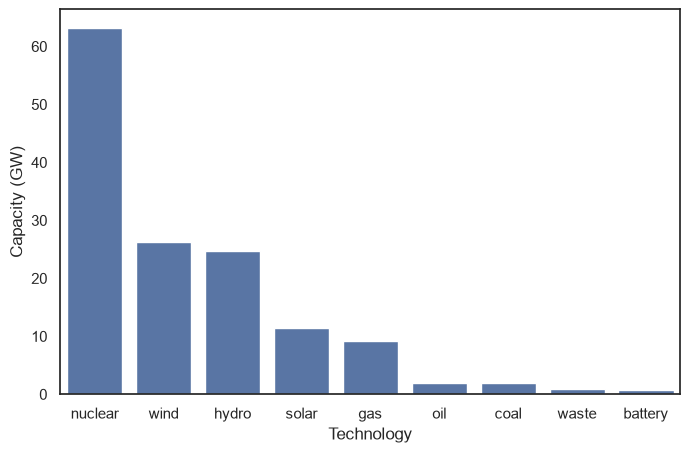

In [37]:
# pd.read_clipboard().assign().to_feather('./data/processed/FR_gen_composition.feather')
# pd.read_feather('./data/processed/FR_gen_composition.feather').assign(Output=pd.read_feather('./data/processed/FR_gen_composition.feather')['Output'].str.split(' MW').apply(lambda r: int(r[0].replace(',', ''))/1000)).to_feather('./data/raw/FR_gen_composition.feather')
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 5), sharex=True, sharey=True)
sns.barplot(pd.read_feather('./data/processed/FR_gen_composition.feather'), x='Source', y='Output', ax=ax)
ax.set_ylabel('Capacity (GW)')
ax.set_xlabel('Technology')
# pd.read_feather('./data/processed/FR_gen_composition.feather')